In [1]:
from IPython.display import display, Markdown
import itertools as itls
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mytools.dframe_tools import index_dframe, change_dframe_labels
from mytools.dict_tools import append_dicty
from mytools.misc import assign_participant_numbers
from mytools.my_seaborn import load_seaborn_prefs, plot_bar, plot_line, init_markers, multifig_formatter, \
    add_custom_error
from mytools.string_tools import misc_symbols


In [2]:
"""
Settings for plots
"""
# Init
og_dir = os.getcwd()  # Directory of current file
participants = [f"p{i + 1}" for i in range(8)]  # P1 to P8
sf_list = [2, 8, 16]
sym = misc_symbols()  # Codes for symbols used in figure labels
markers = init_markers()  # List of all possible markers on matplotlib

# Implement new orientation labels in plots
old_ori_labels = ['horizontal', 'vertical', 'minus45', 'plus45']
ori_labels = [f"0{sym['deg']}", f"90{sym['deg']}", f"45{sym['deg']}", f"135{sym['deg']}"]

# Plot settings for each experiment
plot_settings = {
    'Contrast Detection': {
        'path': os.path.join(og_dir, 'Contrast Detection'),
        'ylabel': f"Threshold (%)",
        'ylim': (0, 30), 'log_ylim': (0.1, 30), 'mean_ylim': (0, 15),
        'ratio_ylim': (0, 3), 'ratio_log_ylim': (0.6, 10),
    },
    'Orientation Discrimination': {
        'path': os.path.join(og_dir, 'Orientation Discrimination'),
        'ylabel': f"Threshold ({sym['deg']})",
        'ylim': (0, 15), 'log_ylim': (0.1, 20), 'mean_ylim': (0, 6),
        'ratio_ylim': (0, 8), 'ratio_log_ylim': (0.6, 10),
    },
}

# Global plot settings to apply to all plots
for i_exp in plot_settings:
    plot_settings[i_exp]['xlabel'] = f"Spatial frequency ({sym['cpd']})"
    plot_settings[i_exp]['dpi'] = 300

# Apply plot configuration settings through mpl.rcParams
custom_rc = {
    'axes.titlesize': 26, 'axes.labelsize': 22,
    'xtick.labelsize': 22, 'ytick.labelsize': 22,
    'legend.fontsize': 21, 'legend.title_fontsize': 21, 'legend.handletextpad': 0.25,
    'lines.linewidth': 0.4,
}
load_seaborn_prefs(custom_rc=custom_rc)

# Color palette for orientation conditions
cblind = sns.color_palette('colorblind')
c_palette = [cblind[0], cblind[1], cblind[2], cblind[3]]

# Color range for plots showing all participants data (e.g. ratio plot)
rgb_1 = (0.2, 0.5, 0.8)  # Blue
rgb_2 = (0.8, 0.5, 0.2)  # Orange
c_palette_ps = sns.blend_palette([rgb_1, rgb_2], as_cmap=False, n_colors=len(participants))


In [3]:
'''
Format data for each experiment
'''
# Init
plot_data = {k: {} for k in plot_settings}

# Format data for each experiment
for i_exp in plot_settings:
    # Settings for this experiment
    info = plot_settings[i_exp]

    # Paths
    data_dir = os.path.join(info['path'], 'Analysis')
    graph_dir = os.path.join(info['path'], 'Graphs')
    if not os.path.exists(graph_dir):
        os.makedirs(graph_dir)

    # Load data
    raw_data = pd.read_csv(os.path.join(data_dir, 'raw_anonymised.csv'))
    indiv_data = pd.read_csv(os.path.join(data_dir, 'indiv_thresholds.csv'))
    mean_data = pd.read_csv(os.path.join(data_dir, 'mean_thresholds.csv'))
    ratio_data = pd.read_csv(os.path.join(data_dir, 'ratios.csv'))

    # Update ori labels for plots
    raw_data = change_dframe_labels(raw_data, 'orientation', old_ori_labels, ori_labels)
    indiv_data = change_dframe_labels(indiv_data, 'orientation', old_ori_labels, ori_labels)
    mean_data = change_dframe_labels(mean_data, 'orientation', old_ori_labels, ori_labels)

    # Add empty data for participants who didn't perform 8 c/deg
    for i_p, i_ori in itls.product(participants, ori_labels):
        if index_dframe(raw_data, ['participant', 'orientation', 'spatial frequency'],
                        [i_p, i_ori, 8]
                        ).empty:
            raw_data.loc[len(raw_data)] = ['', i_p, i_ori, 8, np.nan]
    # Do the same for OEI scores
    ratio_data = index_dframe(ratio_data, ['ratio'], ['OEI'])  # Index OEI scores
    for i_p, i_sf in itls.product(participants, sf_list):
        if index_dframe(ratio_data, ['participant', 'spatial frequency'], [i_p, i_sf]
                        ).empty:
            ratio_data.loc[len(ratio_data)] = [i_p, i_sf, 'OEI', np.nan]

    # Store formatted plot data
    plot_data[i_exp]['raw'] = raw_data
    plot_data[i_exp]['indiv_thresh'] = indiv_data
    plot_data[i_exp]['mean_thresh'] = mean_data
    plot_data[i_exp]['ratio'] = ratio_data
    plot_data[i_exp]['geomean_ratio'] = pd.read_csv(os.path.join(data_dir, 'geomean_ratios.csv'))


## **Experiment: Contrast Detection**

**Individual Thresholds Plot:**

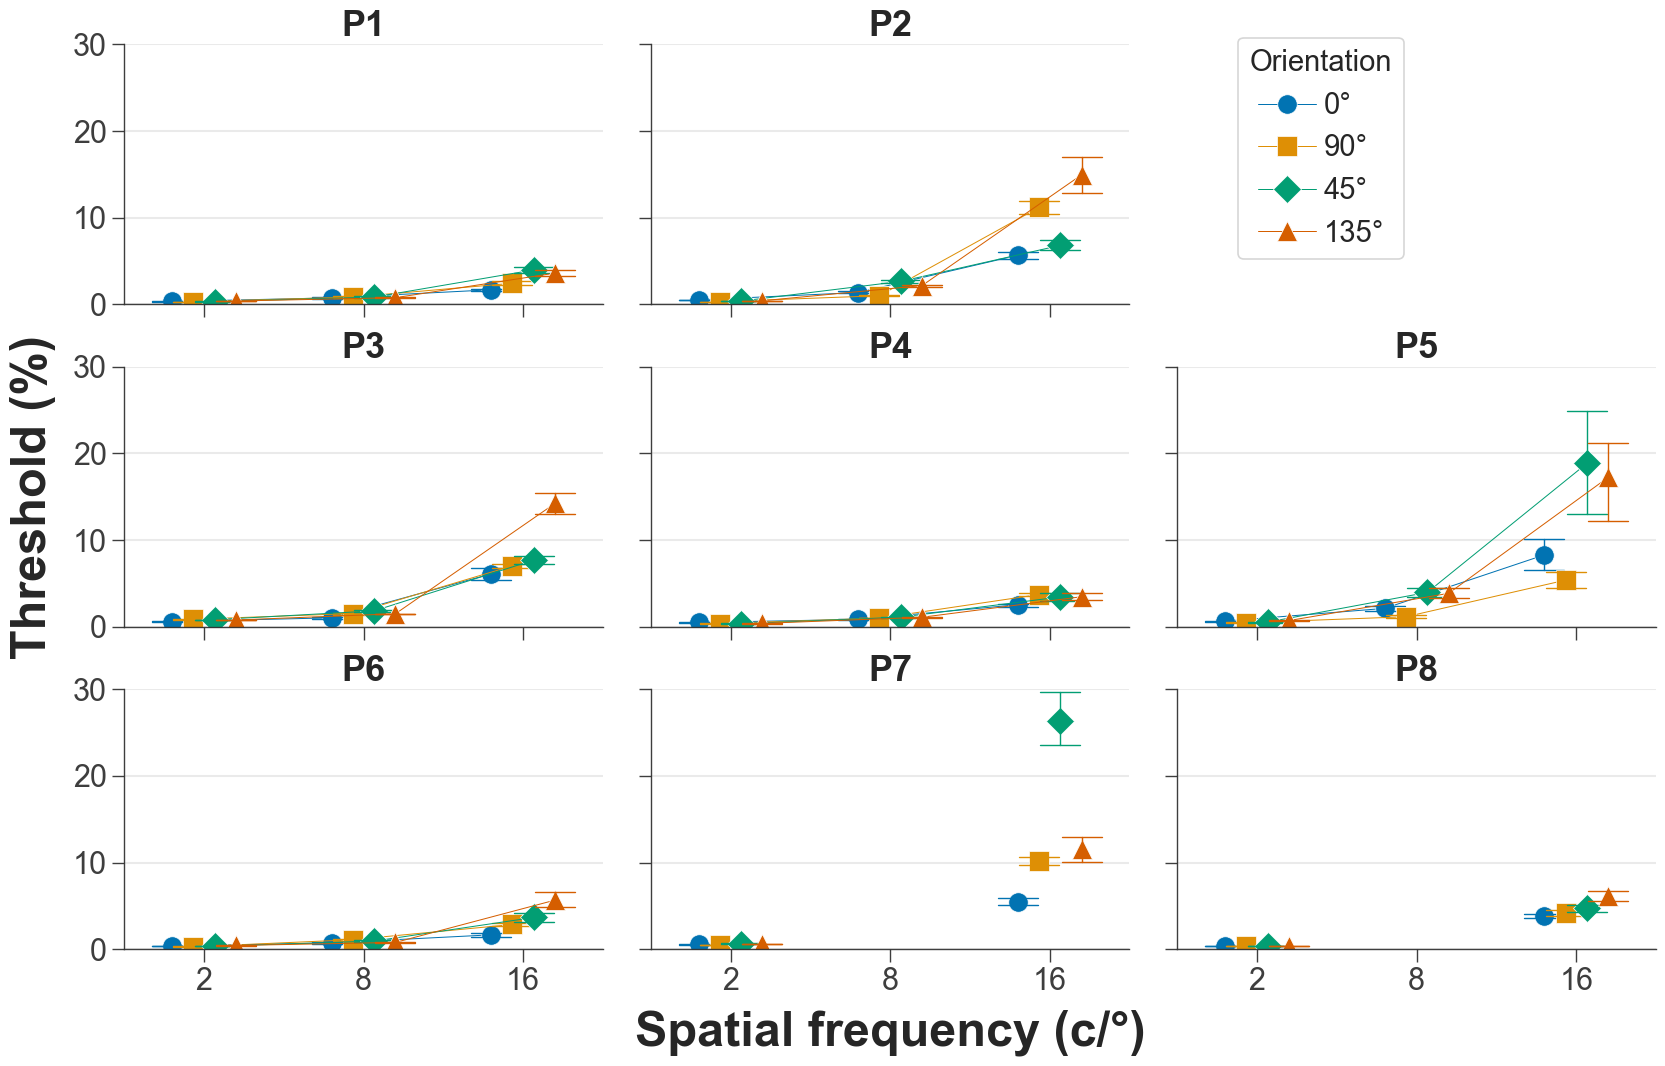

## **Experiment: Orientation Discrimination**

**Individual Thresholds Plot:**

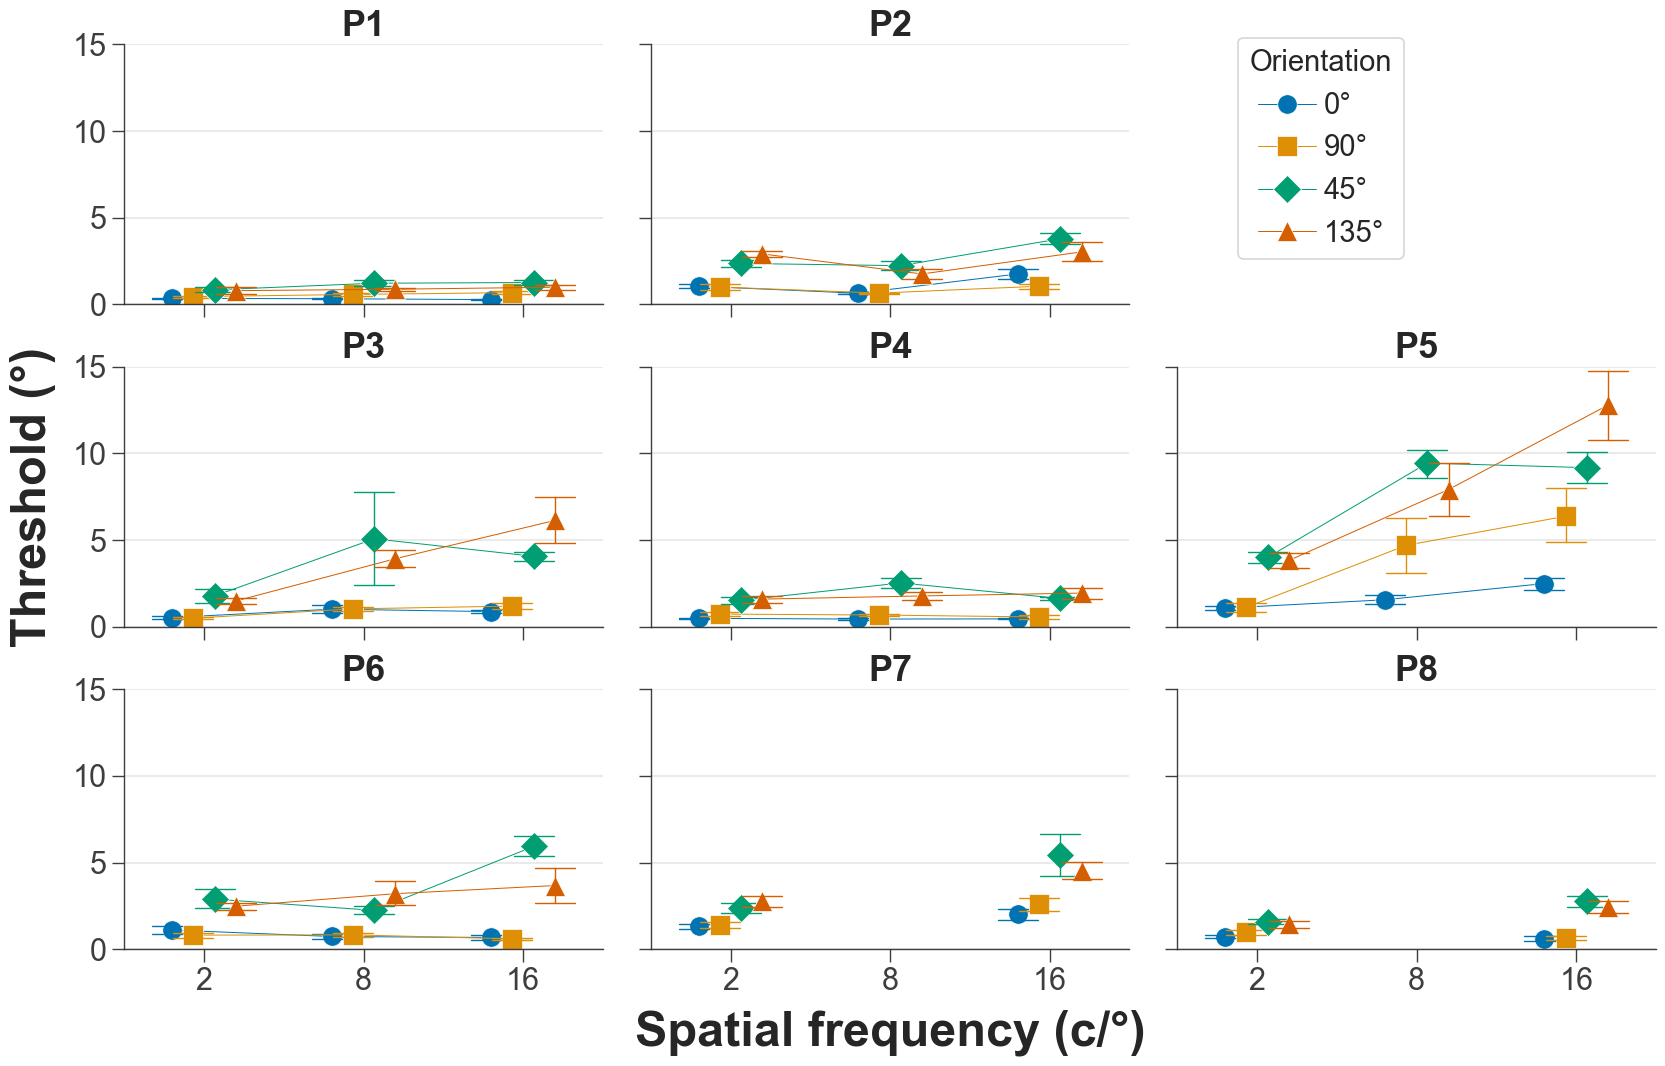

In [4]:
'''
Plot thresholds for each participant
'''
for i_exp in plot_settings:
    raw_data = plot_data[i_exp]['raw']
    info = plot_settings[i_exp]  # Settings for this experiment
    p_list = [p for p in participants]

    # Initialise plot window
    fig, axes = plt.subplots(3, 3, figsize=[17, 11], facecolor='w')
    axes = list(axes.flatten())

     # Plot thresholds for each participant in single figure
    for idx, ax in enumerate(axes):
        ax.set_clip_on(False)  # Allow legend to exceed bounds of axes object
        # Skip the 3rd column 1st row (legend goes here)
        if idx == 2:
            ax.set_visible(False)
            continue
        # Specify participant name for this plot
        i_p = p_list.pop(0)
        p_dframe = raw_data[raw_data['participant'] == i_p]

        n_hues = len(p_dframe['orientation'].unique())
        _, ax = plot_line(
            p_dframe, x='spatial frequency', y='threshold', hue='orientation',
            hue_order=ori_labels, palette=c_palette,
            ci=68,  # Approximates SEM
            title=f"{i_p}", title_y=1, legend=False,
            x_label=info['xlabel'], y_label=info['ylabel'], y_lim=info['ylim'],
            markers=markers[:n_hues], dodge=0.4, capsize=0.25, errwidth=1,
            ax=ax, fig=fig,
        )
        # Formatting
        [_line.set_markersize(14) for _line in ax.lines]
        ax.yaxis.grid(which='both', linestyle='-', alpha=0.4)

    # Format axes labels of multi-figure
    fig = multifig_formatter(fig, x_label=info['xlabel'],
                             y_label=info['ylabel'], fontsize=35
                             )
    axes[1].legend(loc="center").set(title='Orientation', bbox_to_anchor=[1.4, 0.6])  # Legend

    # Gaps between axes - must be after .tight_layout()
    fig.subplots_adjust(wspace=0.1, hspace=0.24)
    plt.close(fig)

    # - Jupyter Output
    display(Markdown(f"## **Experiment: {i_exp}**"))
    display(Markdown("**Individual Thresholds Plot:**"), fig)



## **Experiment: Contrast Detection**

**Mean Thresholds Plot:**

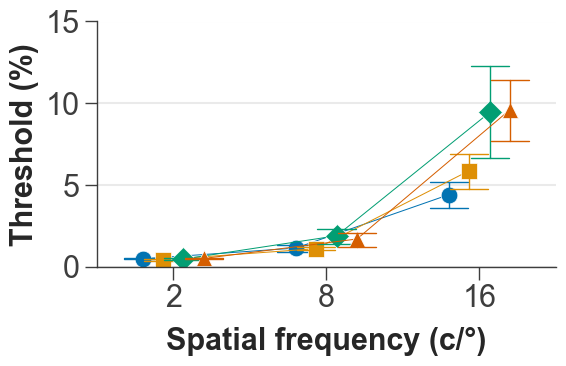

## **Experiment: Orientation Discrimination**

**Mean Thresholds Plot:**

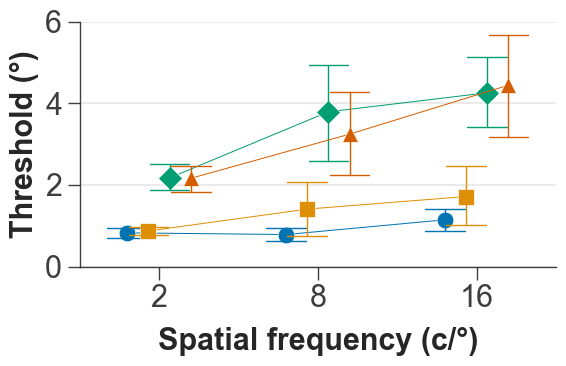

In [5]:
'''
Plot mean thresholds
'''
for i_exp in plot_settings:
    indiv_data = plot_data[i_exp]['indiv_thresh']
    info = plot_settings[i_exp]

    n_hues = len(indiv_data['orientation'].unique())
    fig, ax = plot_line(
        indiv_data, x='spatial frequency', y='mean', hue='orientation',
        hue_order=ori_labels, palette=c_palette, ci=68, title_y=1, legend=False,
        x_label=info['xlabel'], y_label=info['ylabel'], y_lim=info['mean_ylim'],
        markers=markers[:n_hues], dodge=0.4, line_width=1, capsize=0.25, errwidth=1, fig_dims=(6, 4)
    )
    [_line.set_markersize(12) for _line in ax.lines]
    ax.yaxis.grid(which='both', linestyle='-', alpha=0.4)
    plt.close(fig)

    # - Jupyter Output
    display(Markdown(f"## **Experiment: {i_exp}**"))
    display(Markdown("**Mean Thresholds Plot:**"), fig)

## **Experiment: Contrast Detection**

**Ratios Plot:**

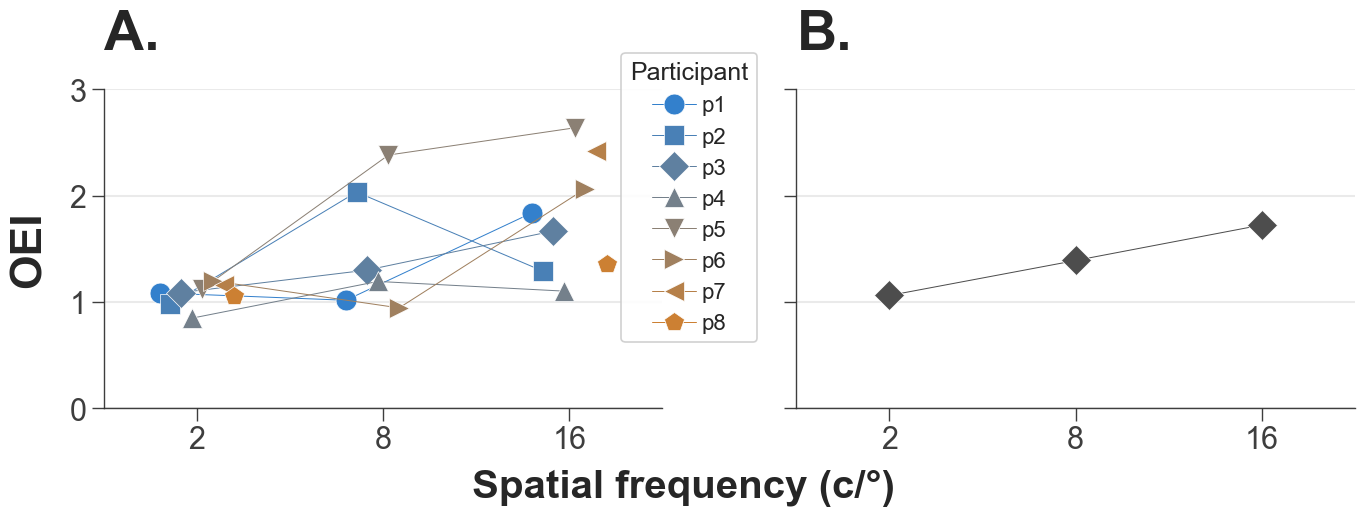

## **Experiment: Orientation Discrimination**

**Ratios Plot:**

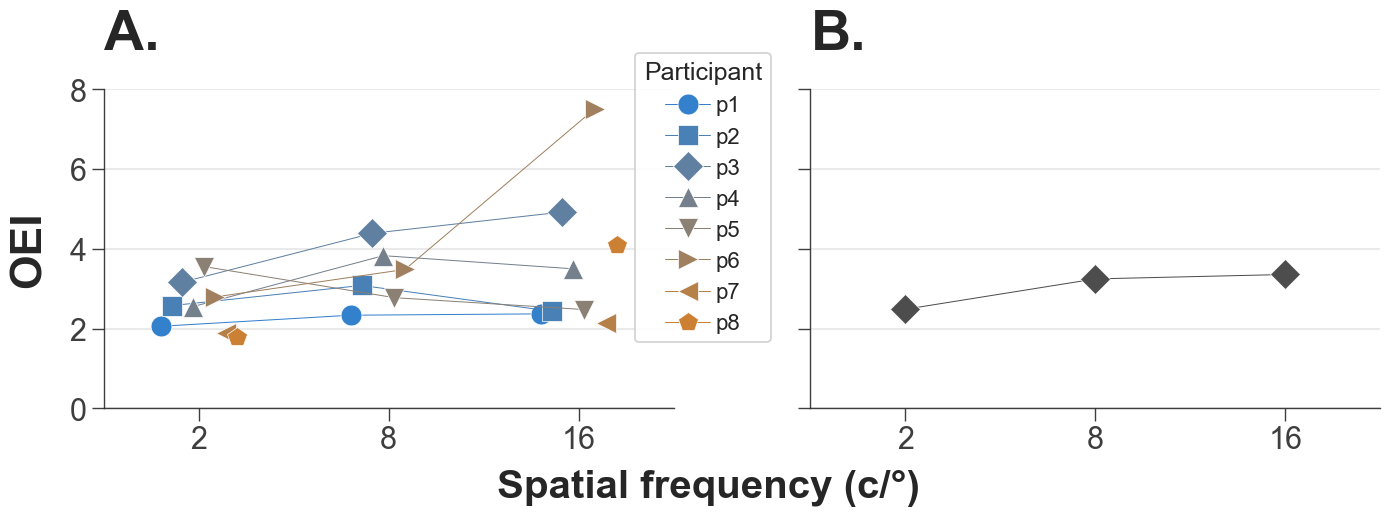

In [8]:
'''
OEI plots
'''
for i_exp in plot_settings:
    ratio_data = plot_data[i_exp]['ratio']
    geomean_ratio_data = plot_data[i_exp]['geomean_ratio']
    info = plot_settings[i_exp]  # Settings for this experiment
    # Line plot
    r_fig, r_axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5.5))
    n_hues = len(ratio_data['participant'].unique())
    _, r_ax0 = plot_line(ratio_data, x='spatial frequency', y='score', hue='participant',
                         hue_order=participants, palette=c_palette_ps, markers=markers[:n_hues], dodge=0.4, line_width=2,
                         legend=False, legend_title='', title=None, y_label='OEI', x_label=info['xlabel'],
                         y_lim=info['ratio_ylim'], ax=r_axes[0],
                         )
    # Formatting
    [_line.set_markersize(15) for _line in r_ax0.lines]
    r_ax0.set_title("A.", loc="left", x=0, y=1.1, fontdict={'fontweight': 'bold',
                                                            'fontsize': 40})
    r_ax0.yaxis.grid(which='both', linestyle='-', alpha=0.4)
    r_ax0.legend(title="Participant", fontsize=16, title_fontsize=18, bbox_to_anchor=[1.19, 1.15],
                 framealpha=0.9)  # Legend

    # PLOT GEOMEAN RATIOS #
    geomean_ratio_data = index_dframe(geomean_ratio_data, ['ratio'], ['OEI'])
    _, r_ax1 = plot_line(geomean_ratio_data, x='spatial frequency', y='score', hue='ratio',
                         legend=False, title=None, ci=None, palette=[[0.3] * 3],
                         markers=["D"], line_width=2,
                         y_label='OEI', ylabel_pad=6, y_lim=info['ratio_ylim'],
                         x_label=f"Spatial frequency ({sym['cpd']})",
                         x_type='cat', alpha=1,
                         ax=r_axes[1]
                         )
    [_line.set_markersize(15) for _line in r_ax1.lines]

    # Formatting
    r_ax1.set_title("B.", loc="left", x=0, y=1.1, fontdict={'fontweight': 'bold',
                                                               'fontsize': 40})
    [_ax.yaxis.grid(which='both', linestyle='-', alpha=0.4) for _ax in r_axes]  # Set grid on both plots
    r_ax1.set(ylabel=" ", yticklabels=[])

    # Shared axis labels
    r_fig.axes[0].set_ylabel('OEI', labelpad=14, fontdict={'fontweight': 'bold', 'fontsize': 32})
    r_fig.text(0.35, 0.05, info['xlabel'], fontdict={'fontweight': 'bold', 'fontsize': 29})
    [_ax.set_xlabel(' ') for _ax in r_fig.axes]

    # Adjust spacing
    r_fig.subplots_adjust(wspace=0.24)  # Must be done after .tight_layout()

    plt.close(r_fig)
    # - Jupyter Output
    display(Markdown(f"## **Experiment: {i_exp}**"))
    display(Markdown("**Ratios Plot:**"), r_fig)